<a href="https://colab.research.google.com/github/shreya5888/AIML-Project-RollNo-2023343/blob/main/Notebook/Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚗 Project 3: Car Price Prediction


---
### 📌 Problem Statement
A used-car marketplace wants to help sellers price their vehicles fairly based on the car's age, mileage, fuel type, and other listing details.

### 🎯 Business Objective
Predict the resale price of a used car from its specifications so that sellers get realistic price suggestions and buyers can spot overpriced listings.

### 💡 Why This Project Matters
Used-car pricing mixes numeric and categorical features and real-world quirks (car age, mileage, ownership history). It is a good step up from simpler regression datasets and close to what you'd see on an e-commerce or resale platform.

### 🗺️ Project Workflow

`Data Collection → Data Cleaning → EDA → Feature Engineering → Model Building → Evaluation → GitHub Docs`



## 1️⃣ Setup & Data Collection
**Download and load the dataset into a pandas DataFrame.**


In [2]:
!pip install -q kagglehub

import os, glob, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (8, 5)

# Folder structure required by the GitHub checklist
for folder in ["Dataset", "Notebook", "Images"]:
    os.makedirs(folder, exist_ok=True)

REQUIRED = {"name", "year", "selling_price", "km_driven", "fuel", "seller_type", "transmission", "owner"}

In [3]:
csv_path = None
try:
    import kagglehub
    kpath = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")
    csvs = glob.glob(os.path.join(kpath, "**", "*.csv"), recursive=True)
    # prefer the classic file; otherwise any csv containing all required columns
    csvs.sort(key=lambda p: "CAR DETAILS FROM CAR DEKHO" not in p)
    for p in csvs:
        if REQUIRED.issubset(set(pd.read_csv(p, nrows=1).columns)):
            csv_path = p
            break
except Exception as e:
    print("Kaggle download failed:", e)

if csv_path is None:
    from google.colab import files
    print("Please upload 'CAR DETAILS FROM CAR DEKHO.csv'")
    up = files.upload()
    csv_path = list(up.keys())[0]

shutil.copy(csv_path, "Dataset/car_details.csv")
df = pd.read_csv("Dataset/car_details.csv")
print("Loaded:", csv_path)
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Loaded: /kaggle/input/vehicle-dataset-from-cardekho/CAR DETAILS FROM CAR DEKHO.csv
Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 2️⃣ Inspect Data & Data Cleaning
**Inspect columns:** `name, year, selling_price, km_driven, fuel, seller_type, transmission, owner`

**Check for missing values and duplicates.**

**Data Cleaning Tasks:**
- Handle missing values in `km_driven` or `selling_price` if present
- Remove duplicate listings
- Extract the brand name from `name` and drop the free-text original if not needed
- Check for and cap unrealistic outliers in `km_driven`

In [4]:
# Step 32: inspect columns
df.info()
print()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4340,1491,Maruti Swift Dzire VDI,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4340.0,NaN,NaN,NaN,2013.090783,4.215344,1992.0,2011.0,2014.0,2016.0,2020.0
selling_price,4340.0,NaN,NaN,NaN,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,NaN,NaN,NaN,66215.777419,46644.102194,1.0,35000.0,60000.0,90000.0,806599.0
fuel,4340,5,Diesel,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,4340,3,Individual,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4340,2,Manual,3892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,4340,5,First Owner,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Step 33: missing values + duplicates
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate rows: 763


In [6]:
# Cleaning task 1: handle missing values in km_driven / selling_price
# Prices can't be guessed -> drop rows missing the target; impute km_driven with median
before = len(df)
df = df.dropna(subset=["selling_price"])
df["km_driven"] = df["km_driven"].fillna(df["km_driven"].median())
print(f"Rows dropped for missing price: {before - len(df)}")

# Cleaning task 2: remove duplicate listings
dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {dups}  |  New shape: {df.shape}")

Rows dropped for missing price: 0
Duplicates removed: 763  |  New shape: (3577, 8)


In [7]:
# Cleaning task 3: extract brand from the free-text 'name' column
df["brand"] = df["name"].str.split().str[0].str.strip().str.title()
# Fix common naming quirks
df["brand"] = df["brand"].replace({"Land": "Land Rover", "Maruti": "Maruti"})
df = df.drop(columns=["name"])          # drop the free-text original
print(df["brand"].value_counts())

brand
Maruti           1072
Hyundai           637
Mahindra          328
Tata              308
Ford              220
Honda             216
Toyota            170
Chevrolet         151
Renault           110
Volkswagen         93
Nissan             52
Skoda              49
Fiat               32
Audi               31
Datsun             29
Bmw                25
Mercedes-Benz      21
Mitsubishi          5
Jaguar              5
Land Rover          5
Volvo               4
Jeep                3
Ambassador          3
Opelcorsa           2
Mg                  2
Force               1
Daewoo              1
Isuzu               1
Kia                 1
Name: count, dtype: int64


count      3577.000000
mean      69250.545709
std       47579.940016
min           1.000000
25%       36000.000000
50%       60000.000000
75%       90000.000000
max      806599.000000
Name: km_driven, dtype: float64


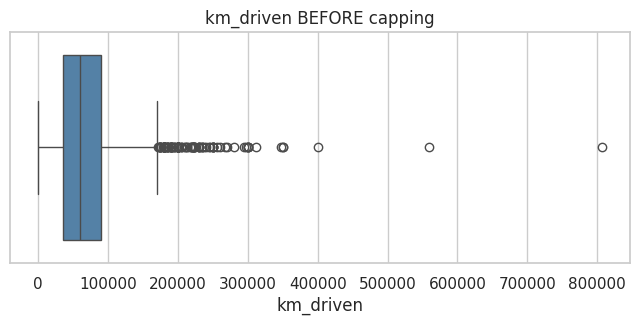

Capped 36 rows above 223,158 km


In [8]:
# Cleaning task 4: check for & cap unrealistic outliers in km_driven
print(df["km_driven"].describe())
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["km_driven"], color="steelblue")
plt.title("km_driven BEFORE capping")
plt.show()

cap = df["km_driven"].quantile(0.99)       # cap at the 99th percentile
n_out = (df["km_driven"] > cap).sum()
df["km_driven"] = df["km_driven"].clip(upper=cap)
print(f"Capped {n_out} rows above {cap:,.0f} km")

## 3️⃣ Feature Engineering (Part 1 – before EDA/correlation)
**Create a `car_age` feature from the `year` column.**

**Feature Engineering Tasks**
- `car_age` = current year − year of manufacture
- Extract `brand` from the car name (✅ done in Section 2)
- Group rare brands into an **'Other'** category (hint) to avoid an explosion of one-hot columns
- Consider log-transforming `selling_price` if heavily skewed

> ✅ *Common mistake avoided:* we use `car_age`, not the raw `year`.

In [9]:
current_year = datetime.now().year
df["car_age"] = current_year - df["year"]
df = df.drop(columns=["year"])             # avoid leaving raw 'year'

# Group rare brands (< 20 listings) into 'Other'
brand_counts = df["brand"].value_counts()
rare = brand_counts[brand_counts < 20].index
df["brand"] = df["brand"].replace(rare, "Other")
print("Brands after grouping:\n", df["brand"].value_counts())

df.head()

Brands after grouping:
 brand
Maruti           1072
Hyundai           637
Mahindra          328
Tata              308
Ford              220
Honda             216
Toyota            170
Chevrolet         151
Renault           110
Volkswagen         93
Nissan             52
Skoda              49
Other              33
Fiat               32
Audi               31
Datsun             29
Bmw                25
Mercedes-Benz      21
Name: count, dtype: int64


,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,car_age
0,60000,70000.0,Petrol,Individual,Manual,First Owner,Maruti,19
1,135000,50000.0,Petrol,Individual,Manual,First Owner,Maruti,19
2,600000,100000.0,Diesel,Individual,Manual,First Owner,Hyundai,14
3,250000,46000.0,Petrol,Individual,Manual,First Owner,Datsun,9
4,450000,141000.0,Diesel,Individual,Manual,Second Owner,Honda,12


In [10]:
# Is selling_price skewed? -> decide on log transform
skew = df["selling_price"].skew()
print(f"Skewness of selling_price: {skew:.2f}")
df["log_price"] = np.log1p(df["selling_price"])
print(f"Skewness of log(selling_price): {df['log_price'].skew():.2f}")

Skewness of selling_price: 5.45
Skewness of log(selling_price): -0.02


## 4️⃣ Exploratory Data Analysis (EDA)
**EDA Tasks asked:**
1. Plot the distribution of `selling_price`
2. Build a correlation heatmap between `car_age`, `km_driven`, `selling_price`
3. Compare average price by **fuel type** and **transmission** using bar plots
4. Scatter-plot `km_driven` vs `selling_price` to visualise the negative relationship

*(Checklist needs ≥ 4 visualizations – we make 6, all saved into `Images/`.)*

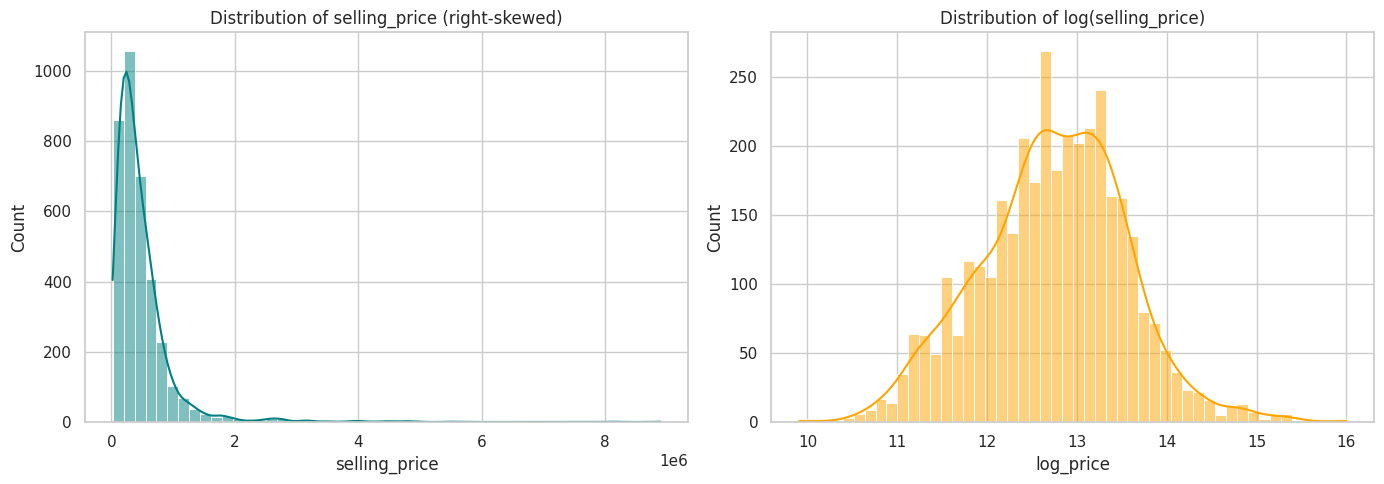

In [11]:
# EDA 1: distribution of selling_price (raw vs log)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["selling_price"], bins=50, kde=True, ax=ax[0], color="teal")
ax[0].set_title("Distribution of selling_price (right-skewed)")
sns.histplot(df["log_price"], bins=50, kde=True, ax=ax[1], color="orange")
ax[1].set_title("Distribution of log(selling_price)")
plt.tight_layout()
plt.savefig("Images/01_price_distribution.png", dpi=150)
plt.show()

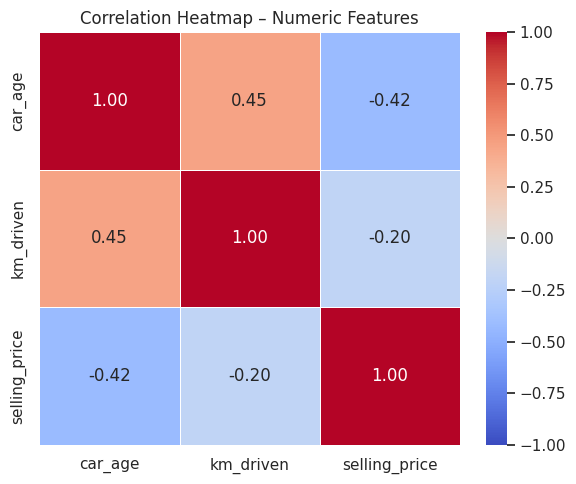

In [12]:
# EDA 2: correlation heatmap (car_age, km_driven, selling_price)
corr_cols = ["car_age", "km_driven", "selling_price"]
plt.figure(figsize=(6, 5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=.5)
plt.title("Correlation Heatmap – Numeric Features")
plt.tight_layout()
plt.savefig("Images/02_correlation_heatmap.png", dpi=150)
plt.show()

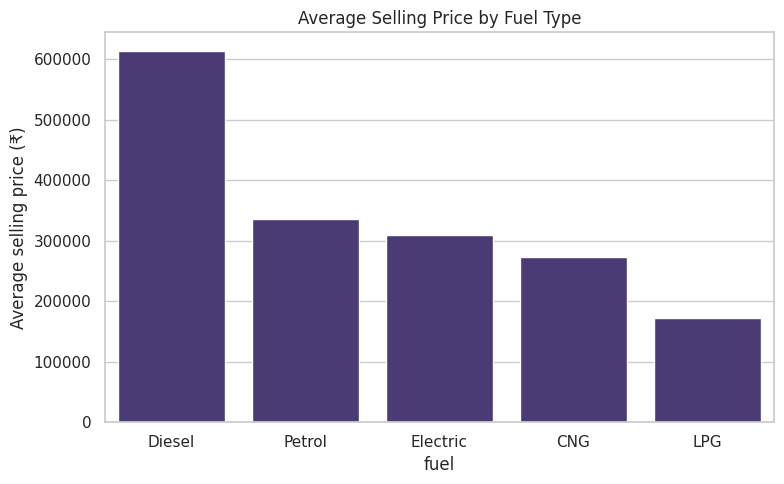

In [13]:
# EDA 3: average price by fuel type
plt.figure(figsize=(8, 5))
order = df.groupby("fuel")["selling_price"].mean().sort_values(ascending=False).index
sns.barplot(data=df, x="fuel", y="selling_price", order=order, estimator=np.mean, errorbar=None)
plt.title("Average Selling Price by Fuel Type")
plt.ylabel("Average selling price (₹)")
plt.tight_layout()
plt.savefig("Images/03_price_by_fuel.png", dpi=150)
plt.show()

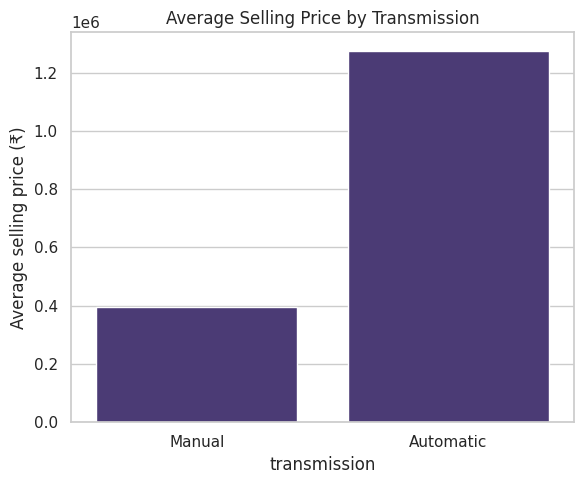

In [14]:
# EDA 4: average price by transmission
plt.figure(figsize=(6, 5))
sns.barplot(data=df, x="transmission", y="selling_price", estimator=np.mean, errorbar=None)
plt.title("Average Selling Price by Transmission")
plt.ylabel("Average selling price (₹)")
plt.tight_layout()
plt.savefig("Images/04_price_by_transmission.png", dpi=150)
plt.show()

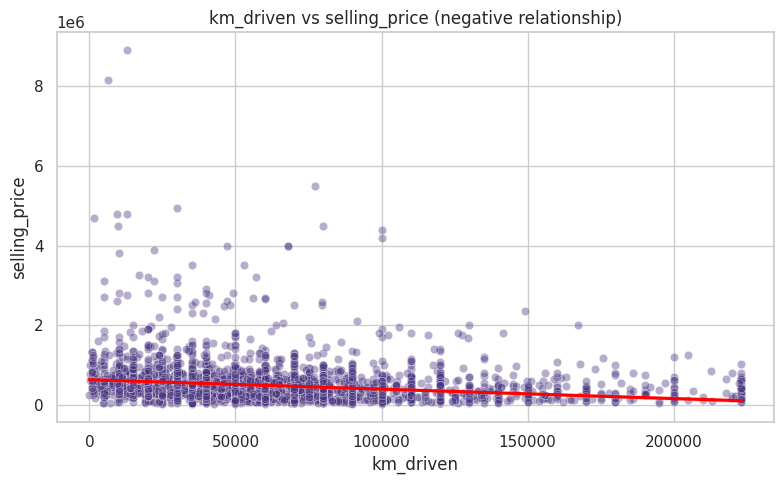

In [15]:
# EDA 5: km_driven vs selling_price scatter (+ regression line)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.4)
sns.regplot(data=df, x="km_driven", y="selling_price", scatter=False, color="red")
plt.title("km_driven vs selling_price (negative relationship)")
plt.tight_layout()
plt.savefig("Images/05_km_vs_price.png", dpi=150)
plt.show()

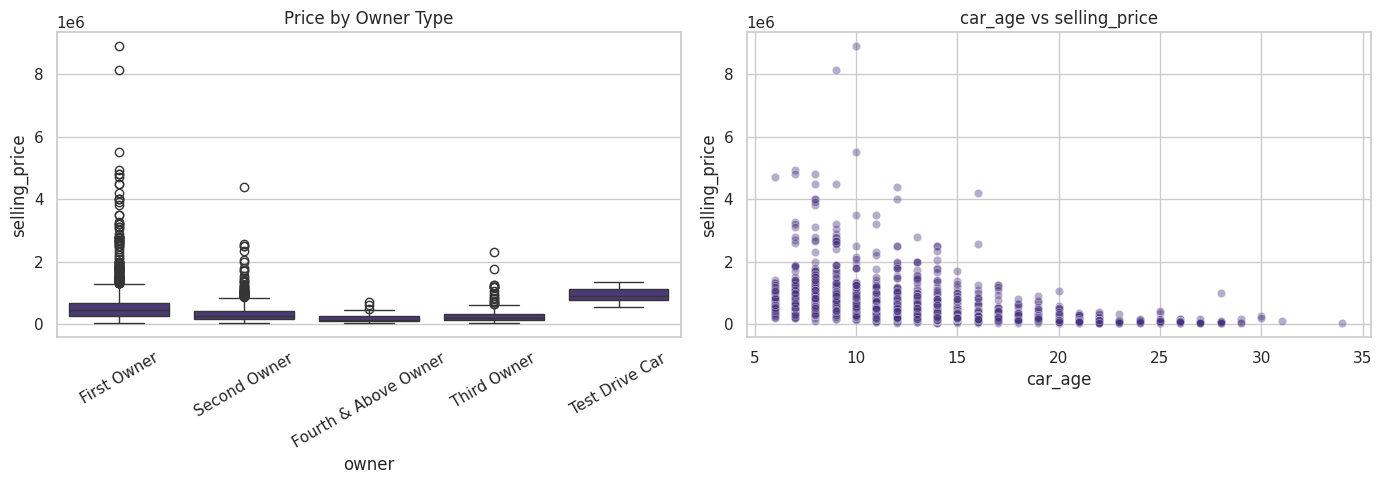

In [16]:
# EDA 6 (bonus): price by owner type and by car age
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="owner", y="selling_price", ax=ax[0])
ax[0].set_title("Price by Owner Type"); ax[0].tick_params(axis="x", rotation=30)
sns.scatterplot(data=df, x="car_age", y="selling_price", alpha=0.4, ax=ax[1])
ax[1].set_title("car_age vs selling_price")
plt.tight_layout()
plt.savefig("Images/06_owner_and_age.png", dpi=150)
plt.show()

## 5️⃣ Correlation Analysis *(ADDITIONAL REQUIREMENT)*
**Run a correlation analysis on numeric features (`car_age`, `km_driven`, `selling_price`).**

This is performed **before** the model is trained, as required.

Correlation matrix:

               car_age  km_driven  selling_price
car_age          1.000      0.447         -0.424
km_driven        0.447      1.000         -0.201
selling_price   -0.424     -0.201          1.000

Correlation with selling_price (sorted by strength):
car_age     -0.424
km_driven   -0.201
Name: selling_price, dtype: float64


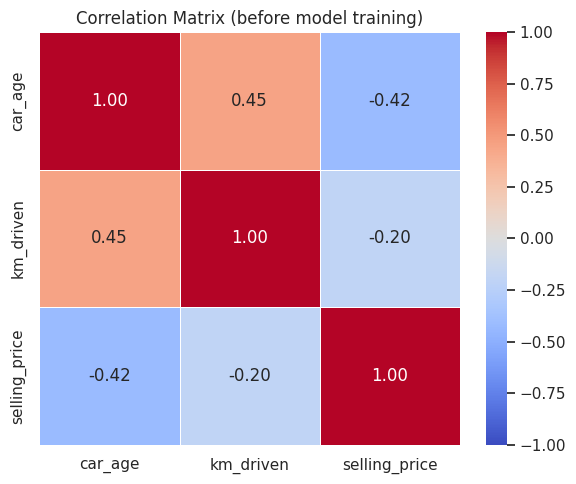

In [17]:
numeric_df = df[["car_age", "km_driven", "selling_price"]]
corr_matrix = numeric_df.corr()
print("Correlation matrix:\n")
print(corr_matrix.round(3))

print("\nCorrelation with selling_price (sorted by strength):")
price_corr = corr_matrix["selling_price"].drop("selling_price").sort_values(key=abs, ascending=False)
print(price_corr.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=.5)
plt.title("Correlation Matrix (before model training)")
plt.tight_layout()
plt.savefig("Images/07_correlation_matrix_final.png", dpi=150)
plt.show()

### 📝 Short Correlation-Analysis
- **`car_age` ↔ `selling_price` – negative correlation.** Older cars have depreciated more, so they sell for less. This is the strongest numeric signal.
- **`km_driven` ↔ `selling_price` – weak/moderate negative correlation.** Higher mileage means more wear, so price drops, but the relationship is weaker because price is also driven by brand, fuel type and segment.
- **`car_age` ↔ `km_driven` – positive correlation.** Older cars have usually been driven more, so these two features overlap somewhat (mild multicollinearity – acceptable for Linear Regression here).

## 6️⃣ Encoding & Train/Test Split
**Encode categorical columns** (`fuel, seller_type, transmission, owner`) + `brand` using **one-hot encoding**.

**Model Building Tasks:**
- Separate features **X** and target **y** (`selling_price`)
- Split into training and test sets **(80/20)**

Because `selling_price` is heavily right-skewed, we train on **`log(selling_price)`** and convert predictions back to ₹ for evaluation.

In [18]:
cat_cols = ["fuel", "seller_type", "transmission", "owner", "brand"]
df_model = pd.get_dummies(df.drop(columns=["selling_price"]), columns=cat_cols, drop_first=True)

X = df_model.drop(columns=["log_price"])
y = df_model["log_price"]             # log-transformed target
y_actual = df["selling_price"]        # original target (for evaluation in ₹)

print("Feature matrix shape:", X.shape)
X.head()

Feature matrix shape: (3577, 30)


,km_driven,car_age,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,...,brand_Mahindra,brand_Maruti,brand_Mercedes-Benz,brand_Nissan,brand_Other,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen
0,70000.0,19,False,False,False,True,True,False,True,False,...,False,True,False,False,False,False,False,False,False,False
1,50000.0,19,False,False,False,True,True,False,True,False,...,False,True,False,False,False,False,False,False,False,False
2,100000.0,14,True,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
3,46000.0,9,False,False,False,True,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
4,141000.0,12,True,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False


In [19]:
# Step 37: 80/20 split
X_train, X_test, y_train, y_test, ya_train, ya_test = train_test_split(
    X, y, y_actual, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (2861, 30)  Test: (716, 30)


## 7️⃣ Model Training
**Train a `LinearRegression` model to predict `selling_price`** and generate predictions on the test set.

In [20]:
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions (log scale) -> convert back to rupees
y_pred_log = model.predict(X_test)
y_pred = np.expm1(y_pred_log)
print("Model trained ✅")

Model trained ✅


## 8️⃣ Evaluation
**Evaluation Tasks:**
- Report **R², MAE, RMSE**
- Plot **predicted vs actual** selling price
- Present the correlation matrix heatmap (✅ Section 5)

In [21]:
r2   = r2_score(ya_test, y_pred)
mae  = mean_absolute_error(ya_test, y_pred)
rmse = np.sqrt(mean_squared_error(ya_test, y_pred))
r2_log = r2_score(y_test, y_pred_log)

print("===== Model Evaluation (original ₹ scale) =====")
print(f"R²   : {r2:.4f}")
print(f"MAE  : ₹{mae:,.0f}")
print(f"RMSE : ₹{rmse:,.0f}")
print(f"\n(R² on log scale – what the model optimised: {r2_log:.4f})")

===== Model Evaluation (original ₹ scale) =====
R²   : 0.6992
MAE  : ₹146,453
RMSE : ₹311,265

(R² on log scale – what the model optimised: 0.7771)


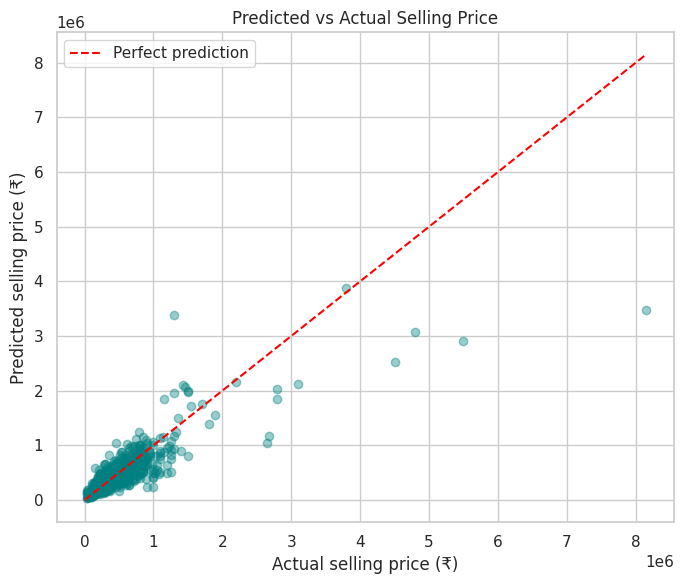

In [22]:
# Predicted vs Actual
plt.figure(figsize=(7, 6))
plt.scatter(ya_test, y_pred, alpha=0.4, color="teal")
lims = [0, max(ya_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual selling price (₹)"); plt.ylabel("Predicted selling price (₹)")
plt.title("Predicted vs Actual Selling Price")
plt.legend(); plt.tight_layout()
plt.savefig("Images/08_predicted_vs_actual.png", dpi=150)
plt.show()

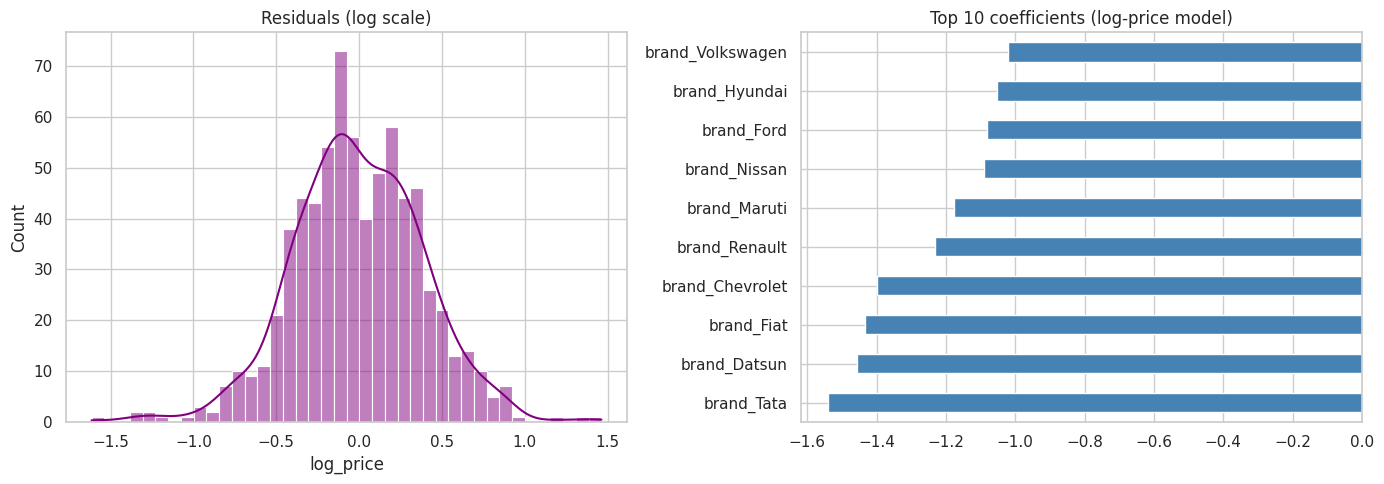

In [23]:
# Bonus: residual plot + top coefficients
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(y_test - y_pred_log, bins=40, kde=True, ax=ax[0], color="purple")
ax[0].set_title("Residuals (log scale)")

coefs = pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False).head(10)
coefs.sort_values().plot(kind="barh", ax=ax[1], color="steelblue")
ax[1].set_title("Top 10 coefficients (log-price model)")
plt.tight_layout()
plt.savefig("Images/09_residuals_coefficients.png", dpi=150)
plt.show()

## 9️⃣ Summary – Which Features Correlate Most with Price?
**Summarize which features correlate most strongly with price.**

In [24]:
print("Ranking of numeric features by |correlation| with selling_price:\n")
print(price_corr.round(3))
print()
print("Strongest numeric driver:", price_corr.index[0])

Ranking of numeric features by |correlation| with selling_price:

car_age     -0.424
km_driven   -0.201
Name: selling_price, dtype: float64

Strongest numeric driver: car_age


### ✍️ Discussion
1. **`car_age`** – strongest negative correlation. Cars lose value every year (depreciation), so newer cars cost more.
2. **`km_driven`** – negative correlation. More kilometres = more wear and tear, lowering resale value.
3. **Categorical drivers (from the model coefficients & bar plots)** – fuel type (diesel/petrol vs CNG/LPG), transmission (automatic > manual) and brand (premium brands > economy brands) strongly shift price even though they aren't part of the numeric correlation matrix.

**Conclusion:** Linear Regression on the engineered features (`car_age`, capped `km_driven`, one-hot categories, brand) gives a reasonable baseline for used-car price suggestions. Next steps: try Ridge/Lasso, tree-based models, or add features like engine size.

# The cell below generates README.md (with your actual metrics), then zips everything for download.

In [25]:
lines = [
"# Car Price Prediction (Linear Regression)",
"",
"## Problem Statement",
"A used-car marketplace wants to help sellers price their vehicles fairly based on the car's age, mileage, fuel type and other listing details.",
"",
"## Business Objective",
"Predict the resale price of a used car from its specifications so sellers get realistic price suggestions and buyers can spot overpriced listings.",
"",
"## Dataset",
"- Vehicle Dataset from CarDekho (Kaggle - nehalbirla): https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho",
f"- Rows after cleaning: {len(df)}",
"",
"## Approach",
"1. Data cleaning: missing values, duplicates, brand extraction, km_driven outlier capping (99th percentile)",
"2. Feature engineering: car_age, brand (rare brands grouped as Other), one-hot encoding, log-transform of selling_price",
"3. EDA: price distribution, correlation heatmap, price by fuel/transmission, km vs price scatter",
"4. Model: LinearRegression, 80/20 train-test split",
"",
"## Additional Requirement: Correlation Analysis (before training)",
"Correlation between numeric features was computed before model training:",
"",
price_corr.round(3).to_frame("corr_with_selling_price").to_markdown(),
"",
"- car_age shows the strongest negative relationship with price (depreciation).",
"- km_driven is also negatively correlated (wear and tear).",
"",
"![Correlation Heatmap](Images/02_correlation_heatmap.png)",
"![Price Distribution](Images/01_price_distribution.png)",
"![km vs Price](Images/05_km_vs_price.png)",
"![Predicted vs Actual](Images/08_predicted_vs_actual.png)",
"",
"## Results",
"| Metric | Value |",
"|---|---|",
f"| R2 | {r2:.4f} |",
f"| MAE | Rs {mae:,.0f} |",
f"| RMSE | Rs {rmse:,.0f} |",
"",
"## Key Insights",
"- Newer, lower-mileage cars sell for more.",
"- Fuel type, transmission and brand shift the price noticeably.",
"",
"## How to Run",
"Open `Notebook/Car_Price_Prediction.ipynb` in Google Colab and run all cells.",
]
with open("README.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))
print("README.md created ✅")

README.md created ✅


In [26]:
# Zip the project folder for easy upload to GitHub, then download
import shutil
from google.colab import files

proj = "AIML-Project-RollNo-XXXXX"      # <-- change XXXXX to your roll number
os.makedirs(proj, exist_ok=True)
for item in ["Dataset", "Images", "Notebook", "README.md"]:
    dest = os.path.join(proj, item)
    if os.path.isdir(item):
        shutil.copytree(item, dest, dirs_exist_ok=True)
    elif os.path.exists(item):
        shutil.copy(item, dest)

shutil.make_archive(proj, "zip", proj)
print("Zip created. Remember to add your .ipynb into the Notebook/ folder before pushing to GitHub.")
files.download(proj + ".zip")

Zip created. Remember to add your .ipynb into the Notebook/ folder before pushing to GitHub.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>